In [1]:
# Uses the chained RF regressor (trained in 4B_5) and the full prediction
# dataframe (built in 4B_6_1) to produce one bias corrected GeoTIFF per day

# WORKFLOW
# 1. Load config, model, and spatial template
# 2. Iterate over days in the period range
# 3. Per day: load rows from parquet, predict, reconstruct DataArray
# 4. Align DataArray to template extent via reproject_match
# 5. Save as float32 GeoTIFF

In [2]:
import os
import joblib
import numpy as np
import pandas as pd
import xarray as xr
import rioxarray as rxr
from tqdm import tqdm

start_year, start_month, start_day = 2001, 1, 1
end_year,   end_month, end_day   = 2005, 12, 1

# Paths
base_dir = r"..\Data\Processed\Bias_correction_daily\Predicted_rasters"
parquet_dir = r"..\Data\Processed\Bias_correction_daily\Predicted_rasters\full_daily_df.parquet"
model_path = r"..\Data\Processed\Bias_correction_daily\Final_model"
out_dir = r"..\Data\Processed\Bias_correction_daily\Predicted_rasters\daily_predictions"
os.makedirs(out_dir, exist_ok=True)
# template grid
template_path = r"..\Data\Datasets\CHIRPS_prec\CHIRPS_prec_19910101.tif"
template = rxr.open_rasterio(template_path)
    
predictor_features = ['y', 'x', 
        'era5l', 'chirps', 'har', 
        'persiann_prec', 'mswep_prec', 
        'gldas_air_temp', 'gldas_lwdown', 'gldas_specific_humidity',
        'gldas_surface_pressure', 'gldas_swdown', 'gldas_wind_speed',
#        'insitu_kriged', 
        'cluster', 'season', 'season_num',
        'elev_mean', 'elev_std', 'elev_max', 'elev_min', 'slope_mean', 
        'aspect_mean', 'elev_smoothed', 'fetch_1000m_dist', 'fetch_1000m_dir',
        'fetch_500m_dist', 'fetch_500m_dir', 'local_relief', 'doy_sin', 'doy_cos']

In [3]:
# Helpers 

SEASONS = {
    'winter':       [12, 1, 2],
    'pre_monsoon':  [3, 4, 5],
    'monsoon':      [6, 7, 8, 9],
    'post_monsoon': [10, 11],
}

def get_season(month):
    for s, months in SEASONS.items():
        if month in months:
            return s
    return None

SEASONS_NUM = {
    1: 'winter',
    2: 'pre_monsoon',
    3: 'monsoon',
    4: 'post_monsoon'
}

def get_season_num(season_str):
    for s_n, s_name in SEASONS_NUM.items():
        if s_name == season_str:
            return s_n
    return None

def day_label(year: int, month: int, day: int) -> str:
    return f"{year}_{month:02d}_{day:02d}"

In [4]:
# load parquet data

import json


daily_parquet = pd.read_parquet(parquet_dir)
daily_parquet["season"] = daily_parquet["month"].apply(get_season)
daily_parquet["season_num"] = daily_parquet["season"].apply(get_season_num)

cluster_list = sorted(daily_parquet["cluster"].unique().tolist())
season_list = list(SEASONS)

#set column for update function
daily_parquet["predicted_prec_class"] = np.nan
daily_parquet["predicted_daily_prec"] = np.nan

# Predict using seasonally different models
for season in season_list:
    print(f"\n Predicting for season: {season}")
    daily_season_df = daily_parquet[daily_parquet["season"] == season].copy()

    #classification
    classifier_model_file = os.path.join(model_path, f"Classifier_{season}_xgb.pkl")
    classifier_model = joblib.load(classifier_model_file)
    meta = json.load(open(os.path.join(model_path, f"feature_metadata_{season}.json")))
    classification_features = meta['classifier_selected_features']
    daily_season_df["predicted_prec_class"] = classifier_model.predict(daily_season_df[classification_features])

    is_wet = daily_season_df["predicted_prec_class"] == 1
    
    wet_df = daily_season_df[is_wet].copy()
    dry_df = daily_season_df[~is_wet].copy()

    dry_df['predicted_daily_prec'] = 0.0
    regressor_model_file = os.path.join(model_path, f"Regressor_{season}_rf.pkl")
    regressor_model = joblib.load(regressor_model_file)

    regression_features = meta['regressor_selected_features']
    wet_df['predicted_daily_prec'] = regressor_model.predict(wet_df[regression_features])

    daily_season_df.update(wet_df)
    daily_season_df.update(dry_df)
    daily_season_df["predicted_daily_prec"] = daily_season_df["predicted_daily_prec"].clip(lower=0) 

    daily_parquet.update(daily_season_df)

daily_parquet.to_parquet(os.path.join(base_dir, "full_daily_predictions.parquet"), index=False)


 Predicting for season: winter

 Predicting for season: pre_monsoon

 Predicting for season: monsoon

 Predicting for season: post_monsoon


In [5]:
# Main prediction loop - predict rasters for each day

day_range = pd.period_range(
    start=pd.Timestamp(start_year, start_month, start_day),
    end=pd.Timestamp(end_year, end_month, end_day),
    freq='D'
)

print(f"Total days to process: {len(day_range)}")

for d in tqdm(day_range, desc = 'Predicting for each day'):
    year = d.year
    month = d.month
    day = d.day
    label = day_label(year, month, day)
    
    outpath = os.path.join(out_dir, f"predicted_prec_{label}.tif")

    if os.path.exists(outpath):
        tqdm.write(f"Output file already exists for {label}, skipping...")
        continue
    
    #filter daily parquet for the specific day
    daily_grid = daily_parquet[
        (daily_parquet["year"] == year) & 
        (daily_parquet["month"] == month) & 
        (daily_parquet["day"] == day)
    ].copy()

    da = daily_grid.set_index(['y', 'x'])['predicted_daily_prec'].to_xarray()
    da = (da
          .rio.write_crs(template.rio.crs)          
          .rio.write_nodata(-9999)
          .rio.write_transform(template.rio.transform())
          .rio.reproject_match(template)
    )

    da.rio.to_raster(outpath, driver='GTiff', dtype='float32', compress='lzw')

print("All daily predictions completed and saved.")

Total days to process: 1796


Predicting for each day: 100%|██████████| 1796/1796 [05:13<00:00,  5.74it/s]

All daily predictions completed and saved.


Sample raster : ..\Data\Processed\Bias_correction_daily\Predicted_rasters\daily_predictions\predicted_prec_2001_01_01.tif
  Shape       : (89, 177)
  CRS         : EPSG:4326
  Min / Max   : 0.00 / 18.73 mm
  Valid pixels: 15753


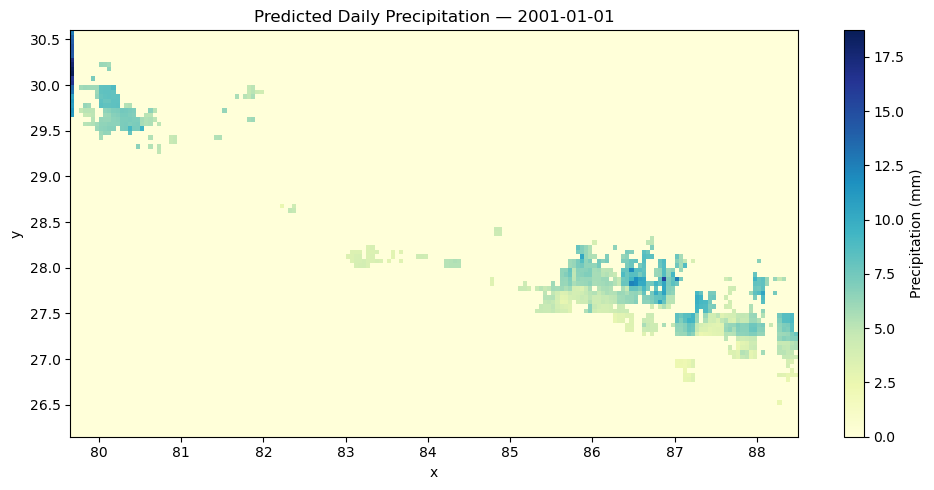

In [6]:
# ── Quick sanity check on one saved raster ───────────────────────────────────

import matplotlib.pyplot as plt

sample_path = os.path.join(out_dir, f"predicted_prec_{day_label(start_year, start_month, start_day)}.tif")

if os.path.exists(sample_path):
    sample = rxr.open_rasterio(sample_path, masked=True).squeeze("band", drop=True)

    print(f"Sample raster : {sample_path}")
    print(f"  Shape       : {sample.shape}")
    print(f"  CRS         : {sample.rio.crs}")
    print(f"  Min / Max   : {float(sample.min()):.2f} / {float(sample.max()):.2f} mm")
    print(f"  Valid pixels: {int((~sample.isnull()).sum())}")

    fig, ax = plt.subplots(figsize=(10, 5))
    sample.plot(ax=ax, cmap="YlGnBu", cbar_kwargs={"label": "Precipitation (mm)"})
    ax.set_title(f"Predicted Daily Precipitation — {start_year}-{start_month:02d}-{start_day:02d}")
    plt.tight_layout()
    plt.show()
else:
    print(f"Sample file not found: {sample_path}")